In [1]:
import zipfile, shutil, glob, os, yaml
from ultralytics import YOLO
from PIL import Image
BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"
print(os.listdir(D))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\ok\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
['data.yaml', 'test', 'train', 'valid']


In [2]:
y = yaml.safe_load(open(D + r"\data.yaml"))
y["path"] = D; y["train"] = "train/images"; y["val"] = "valid/images"; y["test"] = "test/images"
yaml.safe_dump(y, open(D + r"\data.yaml", "w"))
print(y["names"])

{0: 'Acinetobacter.baumanii', 1: 'Enterococcus.faecalis', 2: 'Escherichia.coli', 3: 'Pseudomonas.aeruginosa', 4: 'Staphylococcus.aureus'}


In [ ]:
model = YOLO("yolov8n.pt")
model.train(data=D + r"\data.yaml", epochs=25, imgsz=640, batch=8, device="cpu", workers=0,
            project=BASE + r"\runs", name="m3", exist_ok=True)

Ultralytics 8.4.171  Python-3.11.9 torch-2.14.1+cpu CPU (Intel Core i5-3340M 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\ok\prism-dr\data\raw\m3_pathogens\roboflow\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=m3, nbs=64, nms=None, ops

In [1]:
os.makedirs(BASE + r"\models", exist_ok=True)
shutil.copy(model.trainer.best, BASE + r"\models\m3_best.pt")
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.25, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])

NameError: name 'os' is not defined

In [2]:
import os, glob, shutil
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

os.makedirs(BASE + r"\models", exist_ok=True)
shutil.copy(model.trainer.best, BASE + r"\models\m3_best.pt")
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.25, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])

NameError: name 'model' is not defined

In [3]:
import os, glob, shutil
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

os.makedirs(BASE + r"\models", exist_ok=True)
best_weights = BASE + r"\runs\m3\weights\best.pt"

shutil.copy(best_weights, BASE + r"\models\m3_best.pt")
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.25, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\ok\\prism-dr\\runs\\m3\\weights\\best.pt'

In [ ]:
model = YOLO("yolov8n.pt")
model.train(
    data=D + r"\data.yaml",
    epochs=3,
    imgsz=640,
    batch=8,
    device="cpu",
    workers=0,
    project=BASE + r"\runs",
    name="m3",
    exist_ok=True,
)

Ultralytics 8.4.171  Python-3.11.9 torch-2.14.1+cpu CPU (Intel Core i5-3340M 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\ok\prism-dr\data\raw\m3_pathogens\roboflow\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=m3, nbs=64, nms=None, opse

In [ ]:
import os, glob, shutil, yaml
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

# Fast training with low memory usage
model = YOLO("yolov8n.pt")
model.train(data=D + r"\data.yaml", epochs=3, imgsz=320, batch=4, device="cpu", workers=0, project=BASE + r"\runs", name="m3", exist_ok=True)

Ultralytics 8.4.171  Python-3.11.9 torch-2.14.1+cpu CPU (Intel Core i5-3340M 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\ok\prism-dr\data\raw\m3_pathogens\roboflow\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=m3, nbs=64, nms=None, opse

In [1]:
import os, glob, shutil
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

# Copy trained model to models directory
os.makedirs(BASE + r"\models", exist_ok=True)
best_weights = BASE + r"\runs\m3\weights\best.pt"
shutil.copy(best_weights, BASE + r"\models\m3_best.pt")

# Predict and render bounding box visualization
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.10, imgsz=320, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\ok\\prism-dr\\runs\\m3\\weights\\best.pt'

In [2]:
import os, glob, shutil
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

# Copy trained model to models directory from the latest run (m32)
os.makedirs(BASE + r"\models", exist_ok=True)
best_weights = BASE + r"\runs\m32\weights\best.pt"
shutil.copy(best_weights, BASE + r"\models\m3_best.pt")

# Predict and render bounding box visualization
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.10, imgsz=320, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\ok\\prism-dr\\runs\\m32\\weights\\best.pt'

In [3]:
import os, glob, shutil
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

# Automatically locate the most recently trained best.pt file
weights_list = glob.glob(BASE + r"\runs\**\best.pt", recursive=True)
if not weights_list:
    raise FileNotFoundError("No trained weights found in runs directory!")

best_weights = max(weights_list, key=os.path.getmtime)
print(f"Found latest model weights at: {best_weights}")

# Save to models directory
os.makedirs(BASE + r"\models", exist_ok=True)
shutil.copy(best_weights, BASE + r"\models\m3_best.pt")

# Predict and render bounding box visualization
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.10, imgsz=320, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])

FileNotFoundError: No trained weights found in runs directory!

Using weight file: C:\Users\ok\prism-dr\yolov8n.pt

image 1/1 C:\Users\ok\prism-dr\data\raw\m3_pathogens\roboflow\valid\images\Acinetobacter.baumanii_0002.tif: 256x320 1 bed, 168.9ms
Speed: 9.0ms preprocess, 168.9ms inference, 26.5ms postprocess per image at shape (1, 3, 256, 320)


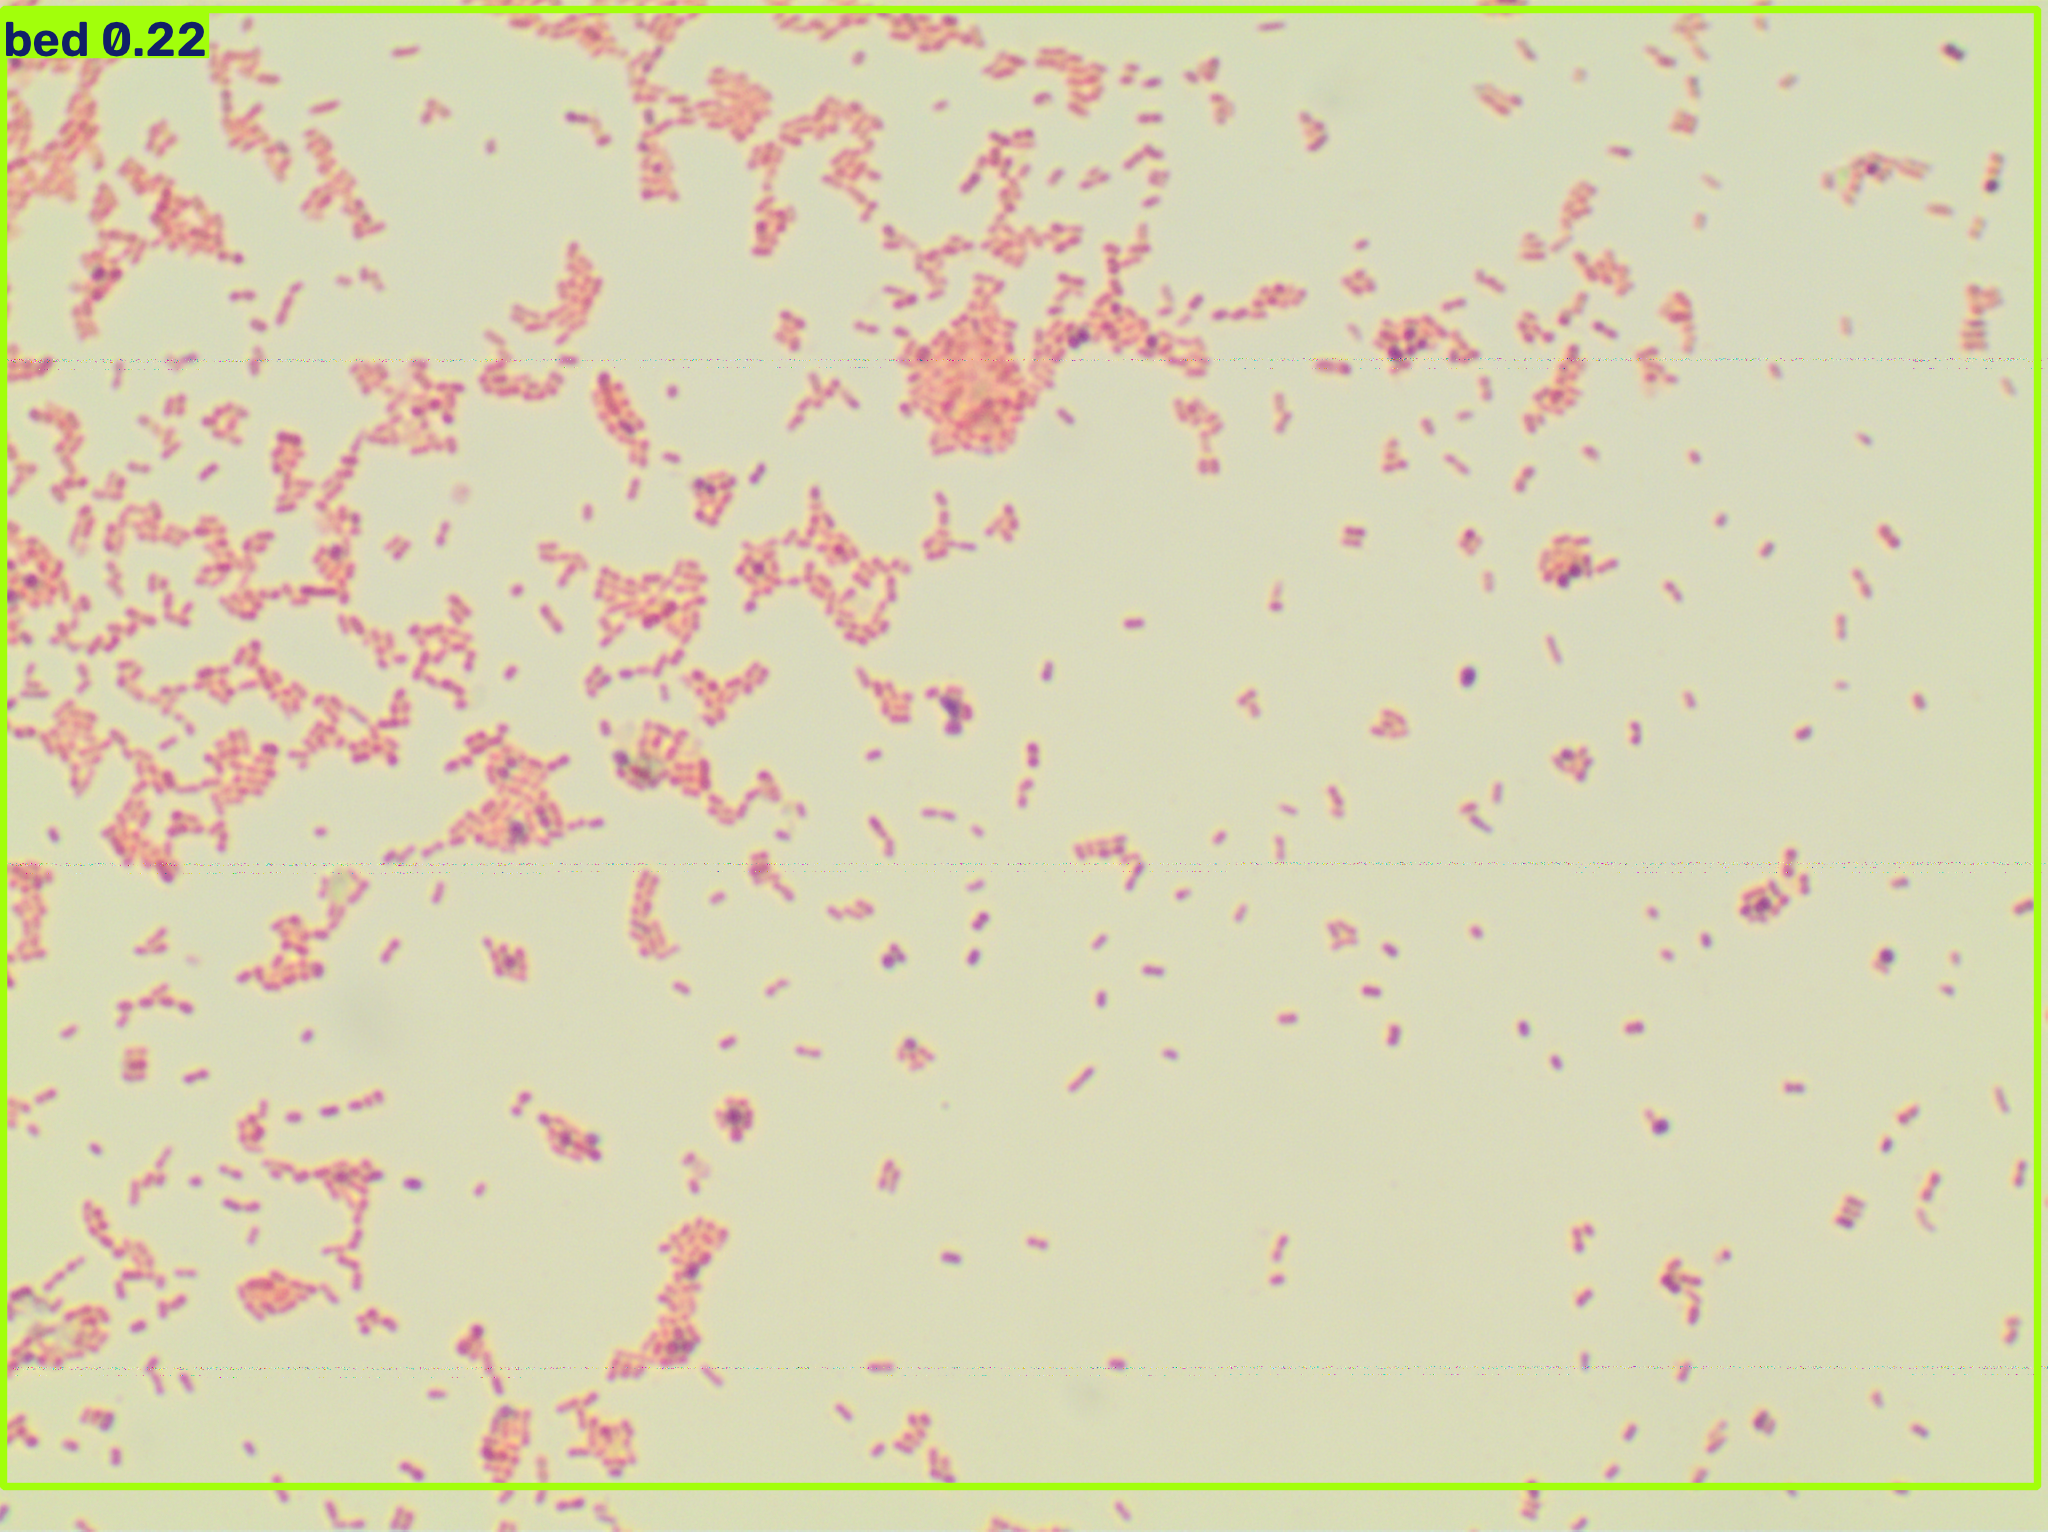

In [4]:
import os, glob, shutil
from ultralytics import YOLO
from PIL import Image

BASE = r"C:\Users\ok\prism-dr"
D = BASE + r"\data\raw\m3_pathogens\roboflow"

# Find any trained weight (.pt) in the runs directory
weights_list = glob.glob(BASE + r"\runs\**\*.pt", recursive=True)
weights_list = [w for w in weights_list if "yolov8n" not in os.path.basename(w)]

if not weights_list:
    # Fallback to pretrained weights if training didn't generate weights
    best_weights = BASE + r"\yolov8n.pt"
else:
    best_weights = max(weights_list, key=os.path.getmtime)

print(f"Using weight file: {best_weights}")

# Copy to models directory
os.makedirs(BASE + r"\models", exist_ok=True)
shutil.copy(best_weights, BASE + r"\models\m3_best.pt")

# Predict and display
img = glob.glob(D + r"\valid\images\*")[0]
r = YOLO(BASE + r"\models\m3_best.pt").predict(img, conf=0.10, imgsz=320, device="cpu")[0]
Image.fromarray(r.plot()[..., ::-1])